# Régularisation, sélection de variables et réduction de dimension

**Chapitre 9 — Statistique pour l'Intelligence Artificielle (Licence 2)**

Ce notebook suit le déroulement du chapitre. Il s'exécute de haut en bas. Chaque partie se termine par une section **À retenir**.

**Objectifs**
- Comprendre pourquoi un modèle trop complexe généralise mal.
- Identifier les variables utiles, inutiles et redondantes.
- Comprendre la régularisation et distinguer Ridge et Lasso.
- Comprendre l'objectif de la réduction de dimension et calculer une ACP.

**Prérequis** : régression linéaire, moyenne, variance, écart-type, notions de base en Python et pandas.

**Bibliothèques** : `numpy`, `pandas`, `matplotlib`, `seaborn`, et `scikit-learn` (utilisée uniquement pour vérifier nos calculs).

**Sommaire**
- Partie 0 : Préparation des données
- Partie 1 : Pourquoi simplifier un modèle ?
- Partie 2 : Sélection de variables
- Partie 3 : Régularisation (Ridge et Lasso)
- Partie 4 : Réduction de dimension et ACP
- Partie 5 : Synthèse

## Partie 0 : Préparation des données

### Le jeu de données pour la selection basée sur la correlation

| Variable | Signification |
|---|---|
| `Superficie` | Surface en m² |
| `Chambres` | Nombre de chambres, environ proportionnel à la superficie |
| `Age` | Âge du logement, en années |
| `Distance_Centre` | Distance au centre-ville, en km |
| `Superficie_pieds` | Même surface, en pieds carrés, avec un petit bruit de mesure : **variable redondante** |
| `Bruit_1` à `Bruit_6` | Nombres aléatoires sans lien avec le prix : **variables inutiles** |
| `Prix` | Variable à expliquer (cible) |

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.precision", 3)

In [2]:
df = pd.read_csv("data.csv")
df.head()

,Superficie,Chambres,Age,Distance_Centre,Superficie_pieds,Bruit_1,Bruit_2,Bruit_3,Bruit_4,Bruit_5,Bruit_6,Prix
0,163.83,5.0,5.43,19.41,1764.40,0.23,0.74,0.37,0.63,-1.40,0.33,300.36
1,110.22,3.0,53.82,19.70,1186.86,-0.30,-0.48,0.87,1.48,1.79,1.31,115.56
2,177.38,5.0,1.74,6.12,1909.28,-0.11,0.35,0.77,0.12,0.13,0.82,411.95
3,151.58,4.0,14.45,14.81,1631.72,-0.06,-0.73,-0.41,0.63,0.00,0.34,317.09
4,55.07,2.0,8.58,15.12,592.78,0.67,-0.37,0.76,0.38,-1.23,1.44,95.03


In [20]:
np.linalg.cond(df)

np.float64(30761.251991668538)

### Séparation apprentissage / test

Un modèle doit être évalué sur des données qu'il n'a **pas** vues pendant son entraînement. Nous gardons 80 % des données pour l'apprentissage et 20 % pour le test. Le tirage est fixé par une graine (`seed`) afin que les résultats soient reproductibles.

In [3]:
X = df.drop(columns="Prix")
y = df.Prix

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y, 
    test_size=0.2, 
    random_state=42
)

print(f"Lot d'apprentissage : {len(X_train)}")
print(f"Lot de test : {len(X_test)}")

Lot d'apprentissage : 160
Lot de test : 40


### Fonction d'erreur

L'erreur quadratique moyenne (*mean squared error*, MSE) mesure l'écart moyen entre les valeurs réelles et les prédictions :

$$
\text{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

Plus la MSE est petite, meilleures sont les prédictions.

In [4]:
def mse(y_vrai, y_pred):

    n = len(y_vrai)
    erreur_c = (y_vrai - y_pred) ** 2
    somme = 0
    for i in erreur_c:
        somme += i

    return somme / n
    # return np.mean((y_vrai - y_pred) ** 2)

## Partie 1 : Pourquoi simplifier un modèle ?

### 1.1 Complexité et surapprentissage

Un modèle plus complexe s'ajuste mieux aux données d'apprentissage. Mais s'il s'ajuste aussi au **bruit**, il risque de mal prédire de nouvelles données. Ce phénomène s'appelle le **surapprentissage** (*overfitting*).

### 1.2 Généralisation

L'erreur sur les données d'apprentissage diminue toujours quand la complexité augmente. L'erreur sur les **données de test** diminue d'abord, puis remonte fortement. Le modèle a alors appris le bruit de l'échantillon d'apprentissage.

La capacité d'un modèle à bien prédire des données nouvelles s'appelle la **généralisation** (*generalization*). C'est elle qui compte, et non l'erreur d'apprentissage.

Le phénomène inverse, un modèle trop simple qui n'arrive pas à capturer la structure des données, s'appelle le **sous-apprentissage** (*underfitting*).

**À retenir**
- Un modèle trop complexe apprend le bruit et généralise mal.
- On juge un modèle sur des données de test, jamais sur ses seules données d'apprentissage.
- La régularisation et la sélection de variables servent à réduire la complexité.

## Partie 2 : Sélection de variables

Il s'agit de garder les variables utiles, d'écarter les inutiles et de ne garder qu'une seule variable parmi les redondantes.

### 2.1 Corrélation de Pearson

La corrélation de Pearson mesure la force d'une relation **linéaire** entre deux variables. Elle varie entre -1 et 1 :

$$
r(x, y) = \frac{\sum_{i}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i}(x_i - \bar{x})^2 \sum_{i}(y_i - \bar{y})^2}}
$$

Une valeur proche de 1 ou -1 indique une relation forte, et une valeur proche de 0 une relation faible ou inexistante.

Nous calculons la corrélation avec la formule, puis nous vérifions le résultat avec `np.corrcoef`. Toutes les analyses de cette partie utilisent uniquement les données d'apprentissage.

In [5]:
from feature_correlation import FeatureCorrelation

def correlation(x, y):
    x_c = x - x.mean()
    y_c = y - y.mean()
    return (x_c @ y_c) / np.sqrt((x_c @ x_c) * (y_c @ y_c))

print("Notre fonction :", round(correlation(X_train["Superficie"].to_numpy(), y_train.to_numpy()), 4))
print("np.corrcoef    :", round(np.corrcoef(X_train["Superficie"], y_train)[0, 1], 4))

Notre fonction : 0.9044
np.corrcoef    : 0.9044


### 2.2 Variables redondantes

Deux variables redondantes apportent la même information. Garder les deux n'améliore pas le modèle et rend les coefficients instables. Nous visualisons la matrice de corrélation entre les variables explicatives.

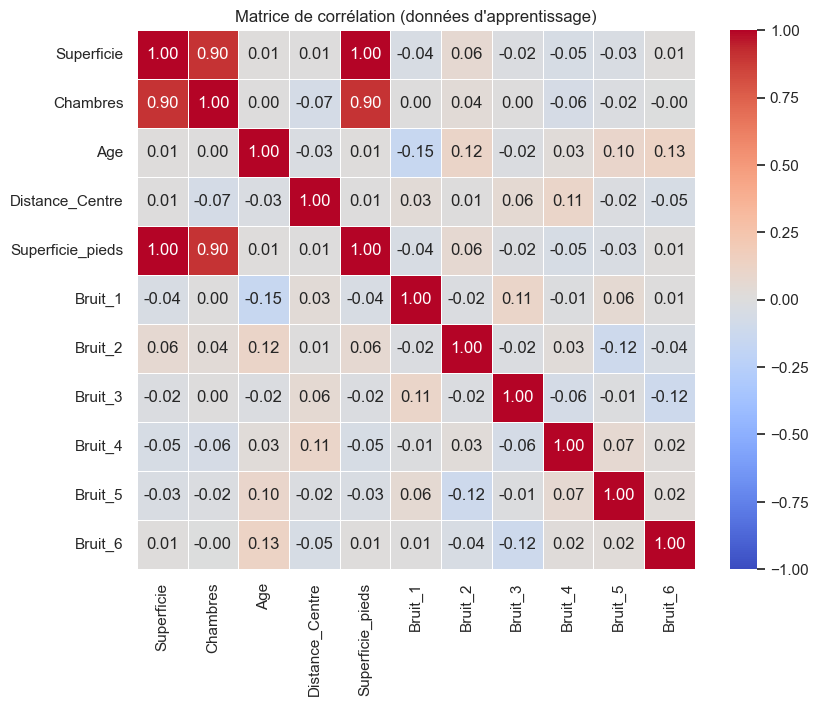

In [6]:
# matrice = X_train.corr()
fc = FeatureCorrelation(X, 0.95)
matrice = fc.obtenir_matrice()

plt.figure(figsize=(9, 7))
sns.heatmap(matrice, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Matrice de corrélation (données d'apprentissage)")
plt.show()

Nous supprimons une variable lorsqu'elle est corrélée à au moins une seille donnée (95 % par exemple) avec une variable déjà retenue. Le seuil est un choix : plus il est bas, plus on supprime de variables. La corrélation entre `Superficie` et `Chambres` est élevée mais inférieure à ce seuil : ces deux variables sont conservées et resteront liées, ce qui servira d'exemple en partie 3.

In [ ]:
variables_retenues = fc.variables_retenues
variables_redondantes = fc.variables_supprimees

print("Variables retenues    :", variables_retenues)
print("Variables redondantes :", variables_redondantes)

X_train_sel = X_train[variables_retenues]
X_test_sel = X_test[variables_retenues]

Variables retenues    : ['Superficie', 'Chambres', 'Age', 'Distance_Centre', 'Bruit_1', 'Bruit_2', 'Bruit_3', 'Bruit_4', 'Bruit_5', 'Bruit_6']
Variables redondantes : ['Superficie_pieds']


### 2.3 Variables utiles et inutiles

Une variable est utile si elle est liée à la cible. Nous classons les variables selon la valeur absolue de leur corrélation avec le prix. Les variables dont la corrélation est inférieure à 0,2 sont considérées comme peu utiles.

Cette méthode ne voit que les relations linéaires. Une variable peut être utile dans une relation non linéaire sans que sa corrélation soit élevée.

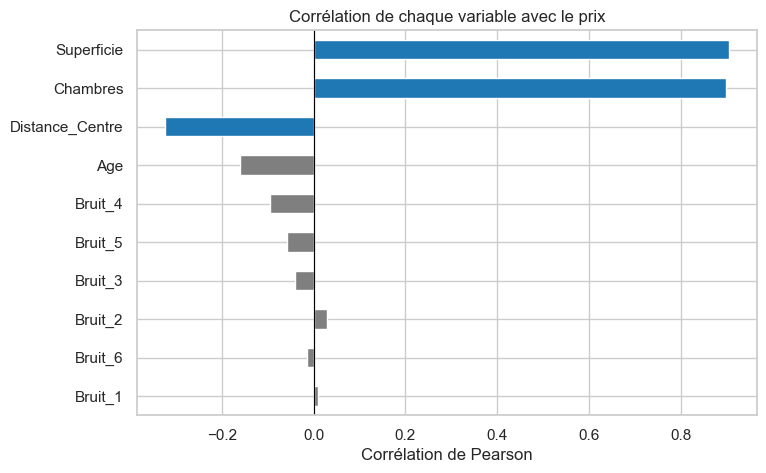

,Corrélation avec Prix
Superficie,0.904
Chambres,0.899
Distance_Centre,-0.324
Age,-0.161
Bruit_4,-0.095
Bruit_5,-0.057
Bruit_3,-0.041
Bruit_2,0.030
Bruit_6,-0.015
Bruit_1,0.009


In [18]:
seuil_utile = 0.2

tab_cible = (
    X_train_sel.join(y_train).corr()["Prix"]
    .drop("Prix")
    .sort_values(key=np.abs, ascending=False)
    .to_frame("Corrélation avec Prix")
)

couleurs = ["tab:blue" if abs(v) >= seuil_utile else "tab:gray" for v in tab_cible["Corrélation avec Prix"]]
tab_cible["Corrélation avec Prix"].plot(kind="barh", color=couleurs)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Corrélation de chaque variable avec le prix")
plt.xlabel("Corrélation de Pearson")
plt.gca().invert_yaxis()
plt.show()

tab_cible.round(3)

In [19]:
variables_utiles = tab_cible.loc[tab_cible["Corrélation avec Prix"].abs() >= seuil_utile].index.to_list()
variables_inutiles = tab_cible.loc[tab_cible["Corrélation avec Prix"].abs() < seuil_utile].index.to_list()


print("Variables utiles    :", variables_utiles)
print("Variables inutiles :", variables_inutiles)

X_train_final = X_train_sel[variables_utiles]
X_test_final = X_test_sel[variables_utiles]

X_train_final

Variables utiles    : ['Superficie', 'Chambres', 'Distance_Centre']
Variables inutiles : ['Age', 'Bruit_4', 'Bruit_5', 'Bruit_3', 'Bruit_2', 'Bruit_6', 'Bruit_1']


,Superficie,Chambres,Distance_Centre
79,165.42,5.0,17.99
197,179.93,5.0,19.84
38,76.31,2.0,8.33
24,164.54,5.0,13.67
122,53.51,2.0,1.68
...,...,...,...
106,111.90,4.0,13.23
14,110.95,4.0,15.98
92,111.39,3.0,6.02
179,159.78,6.0,8.57


**À retenir**
- La corrélation de Pearson ne mesure que les relations linéaires.
- Une variable redondante peut être supprimée sans perte d'information.
- Une variable dont la corrélation avec la cible est proche de 0 est un candidat à la suppression.

## Partie 3 : Régularisation

### 3.1 Principe

Une régression linéaire ajuste les coefficients $\theta$ en minimisant l'erreur. Rien n'empêche alors certains coefficients de devenir très grands, surtout quand deux variables sont redondantes. La **régularisation** ajoute à la fonction de coût une **pénalité** qui freine la taille des coefficients.

- **Ridge** (pénalité L2) :

$$
J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \frac{\lambda}{2}\sum_{j=1}^{p}\theta_j^2
$$

- **Lasso** (pénalité L1) :

$$
J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 + \lambda\sum_{j=1}^{p}|\theta_j|
$$

Le paramètre $\lambda \geq 0$ règle la force de la pénalité. Pour $\lambda = 0$, on retrouve la régression classique (MCO, moindres carrés ordinaires). Plus $\lambda$ augmente, plus les coefficients sont réduits.

Le terme constant (l'ordonnée à l'origine) n'est pas pénalisé.

La différence entre les deux pénalités vient de leur forme : la pénalité L2 réduit tous les coefficients de façon progressive, alors que la pénalité L1 peut annuler certains coefficients complètement.

### 3.2 Préparation des données

Les pénalités dépendent de l'échelle des variables. Une variable mesurée en pieds carrés aurait des coefficients numériquement plus petits qu'en mètres carrés, et serait donc moins pénalisée. Nous **standardisons** donc chaque variable : on lui retire sa moyenne et on la divise par son écart-type.

Les moyennes et écarts-types sont calculés **sur les données d'apprentissage uniquement**, puis appliqués aux données de test. Sinon, des informations du test fuiraient dans l'apprentissage.

In [10]:
def standardiser(X_ref, X_autre):
    moyenne = X_ref.mean(axis=0)
    ecart = X_ref.std(axis=0)
    return (X_ref - moyenne) / ecart, (X_autre - moyenne) / ecart

def predire(X, theta, moyenne_y):
    return moyenne_y + X @ theta

def mco(X, y):
    return np.linalg.lstsq(X, y - y.mean(), rcond=None)[0]

Xa, Xt = standardiser(X_train_sel.to_numpy(), X_test_sel.to_numpy())
ya, yt = y_train.to_numpy(), y_test.to_numpy()
moy_y = ya.mean()
n_app = len(ya)

theta_mco = mco(Xa, ya)

print("Coefficients MCO :")
print(pd.Series(theta_mco, index=X_train_sel.columns).round(2))
print("\nMSE sur le test (MCO) :", round(mse(yt, predire(Xt, theta_mco, moy_y)), 2))

Coefficients MCO :
Superficie         76.27
Chambres           43.65
Age               -18.91
Distance_Centre   -38.44
Bruit_1             1.52
Bruit_2             2.12
Bruit_3             0.62
Bruit_4            -1.45
Bruit_5             1.61
Bruit_6             0.27
dtype: float64

MSE sur le test (MCO) : 851.64


`Superficie` et `Chambres` sont liées (corrélation d'environ 0,9), sans être redondantes. Leurs coefficients MCO sont donc moins stables : un autre échantillon donnerait des valeurs différentes. C'est le problème de la **multicolinéarité** (*multicollinearity*).

### 3.3 Ridge

Le minimum de la fonction de coût Ridge se calcule directement :

$$
\hat{\theta} = (X^\top X + n\lambda I)^{-1} X^\top (y - \bar{y})
$$

Ajouter $n\lambda I$ rend la matrice inversible, même en cas de multicolinéarité. C'est l'idée centrale de Ridge.

In [11]:
def ridge(X, y, lam):
    n, p = X.shape
    yc = y - y.mean()
    return np.linalg.solve(X.T @ X + n * lam * np.eye(p), X.T @ yc)

### 3.4 Lasso

Le Lasso n'a pas de solution directe. On utilise la **descente par coordonnées** (*coordinate descent*) : on met à jour chaque coefficient à tour de rôle, les autres étant fixés. Pour un coefficient $\theta_j$, la mise à jour est :

$$
\theta_j \leftarrow S\!\left(\frac{1}{n} x_j^\top r_j,\ \lambda\right)
\qquad \text{avec} \qquad
S(z, \lambda) = \text{signe}(z)\,\max(|z| - \lambda,\ 0)
$$

Ici $r_j$ désigne le résidu calculé sans la variable $j$. Comme les variables sont standardisées, $\frac{1}{n}x_j^\top x_j = 1$.

La fonction $S$ s'appelle le **seuillage doux** (*soft thresholding*). Elle réduit la valeur de $\lambda$ et met à zéro tout coefficient dont la valeur absolue est inférieure à $\lambda$. C'est ce mécanisme qui produit des coefficients exactement nuls.

In [12]:
def lasso(X, y, lam, n_iter=1000):
    n, p = X.shape
    yc = y - y.mean()
    theta = np.zeros(p)
    for _ in range(n_iter):
        ancien = theta.copy()
        for j in range(p):
            r = yc - X @ theta + X[:, j] * theta[j]
            rho = X[:, j] @ r / n
            theta[j] = np.sign(rho) * max(abs(rho) - lam, 0.0)
        if np.max(np.abs(theta - ancien)) < 1e-8:
            break
    return theta

### 3.5 Vérification avec scikit-learn

Notre code doit donner les mêmes résultats que la bibliothèque de référence. Les paramètres se correspondent ainsi : pour Ridge, `alpha` vaut $n\lambda$ ; pour Lasso, `alpha` vaut $\lambda$.

In [13]:
from sklearn.linear_model import Ridge, Lasso

lam_test = 0.05

ridge_sk = Ridge(alpha=n_app * lam_test).fit(Xa, ya)
lasso_sk = Lasso(alpha=lam_test, max_iter=100000, tol=1e-10).fit(Xa, ya)

print("Écart maximal Ridge :", np.max(np.abs(ridge_sk.coef_ - ridge(Xa, ya, lam_test))))
print("Écart maximal Lasso :", np.max(np.abs(lasso_sk.coef_ - lasso(Xa, ya, lam_test))))

Écart maximal Ridge : 1.4210854715202004e-14
Écart maximal Lasso : 6.908038585606846e-09


### 3.6 Chemin de régularisation

Nous calculons les coefficients pour une suite de valeurs de $\lambda$. La plus grande valeur utile est $\lambda_{\max}$ : au-delà, tous les coefficients Lasso sont nuls.

In [17]:
lam_max = np.max(np.abs(Xa.T @ (ya - moy_y))) / n_app
print(f"lambda_max = {lam_max:.3f}")
print("Coefficients Lasso pour lambda = lambda_max :", np.round(lasso(Xa, ya, lam_max), 4))

lambda_max = 116.667
Coefficients Lasso pour lambda = lambda_max : [ 0.  0. -0. -0.  0.  0. -0. -0. -0. -0.]


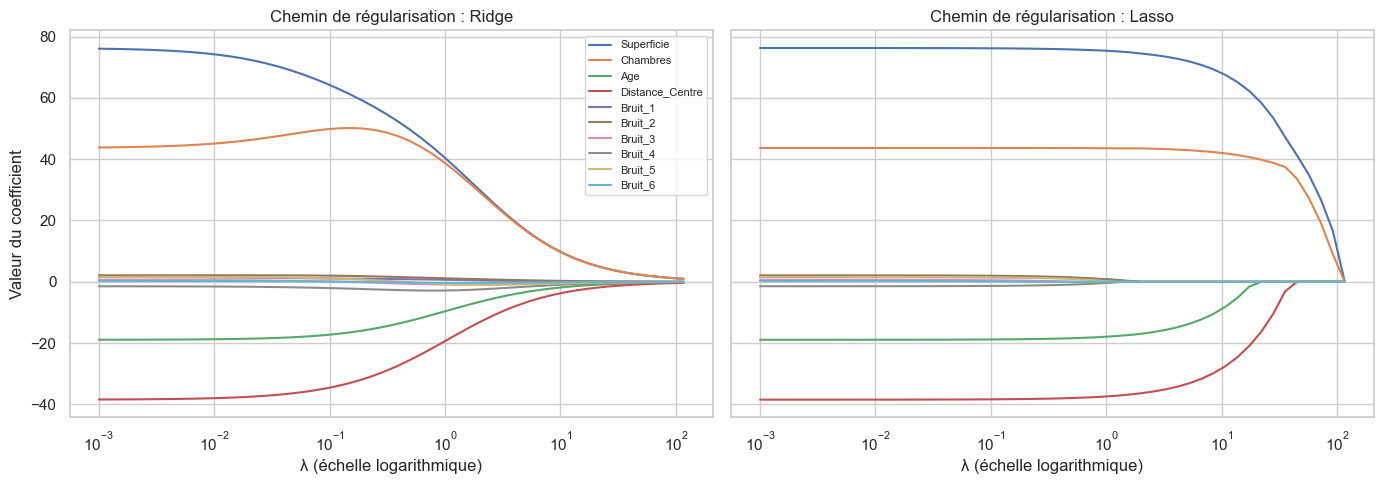

In [22]:
lambdas = np.logspace(-3, np.log10(lam_max), 50)
chemin_ridge = np.array([ridge(Xa, ya, l) for l in lambdas])
chemin_lasso = np.array([lasso(Xa, ya, l) for l in lambdas])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, chemin, titre in zip(axes, [chemin_ridge, chemin_lasso], ["Ridge", "Lasso"]):
    ax.plot(lambdas, chemin)
    ax.set_xscale("log")
    ax.set_xlabel("λ (échelle logarithmique)")
    ax.set_title(f"Chemin de régularisation : {titre}")
axes[0].set_ylabel("Valeur du coefficient")
axes[0].legend(X_train_sel.columns, fontsize=8)
plt.tight_layout()
plt.show()

Avec Ridge, les coefficients diminuent progressivement sans jamais atteindre zéro. Avec le Lasso, les coefficients les moins utiles atteignent zéro l'un après l'autre à mesure que $\lambda$ augmente. Le Lasso effectue donc une sélection de variables automatique.

### 3.7 Choisir $\lambda$ par validation croisée

Le bon $\lambda$ n'est pas connu à l'avance. On utilise la **validation croisée** à 5 plis (*5-fold cross-validation*) : les données d'apprentissage sont découpées en 5 parties. Chaque partie sert à tour de rôle de jeu de validation, pendant que les 4 autres servent à l'entraînement. On choisit le $\lambda$ qui donne la plus petite erreur moyenne.

Le jeu de test reste intact pendant toute cette étape.

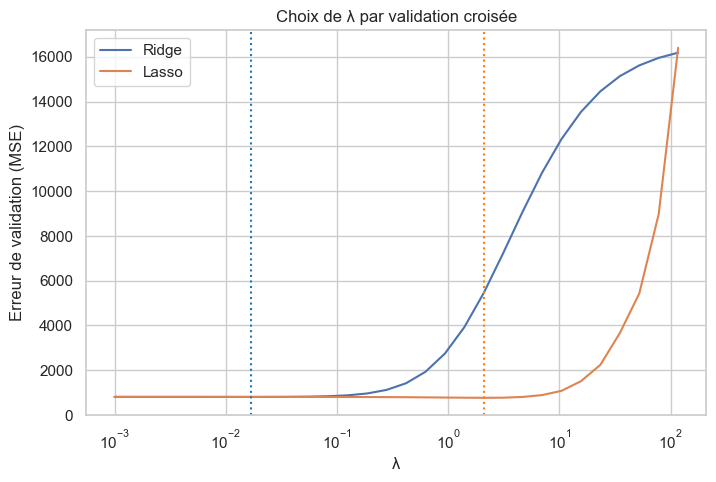

λ retenu pour Ridge : 0.0167
λ retenu pour Lasso : 2.0880


In [23]:
def erreur_validation(X, y, lam, methode, k=5):
    erreurs = []
    for pli in np.array_split(np.arange(len(y)), k):
        masque = np.zeros(len(y), dtype=bool)
        masque[pli] = True
        X_app, X_val = standardiser(X[~masque], X[masque])
        y_app, y_val = y[~masque], y[masque]
        theta = methode(X_app, y_app, lam)
        erreurs.append(mse(y_val, predire(X_val, theta, y_app.mean())))
    return np.mean(erreurs)

Xr, yr = X_train_sel.to_numpy(), y_train.to_numpy()
grille = np.logspace(-3, np.log10(lam_max), 30)

cv_ridge = [erreur_validation(Xr, yr, l, ridge) for l in grille]
cv_lasso = [erreur_validation(Xr, yr, l, lasso) for l in grille]

lam_ridge = grille[np.argmin(cv_ridge)]
lam_lasso = grille[np.argmin(cv_lasso)]

plt.semilogx(grille, cv_ridge, label="Ridge")
plt.semilogx(grille, cv_lasso, label="Lasso")
plt.axvline(lam_ridge, ls=":", color="tab:blue")
plt.axvline(lam_lasso, ls=":", color="tab:orange")
plt.xlabel("λ")
plt.ylabel("Erreur de validation (MSE)")
plt.title("Choix de λ par validation croisée")
plt.legend()
plt.show()

print(f"λ retenu pour Ridge : {lam_ridge:.4f}")
print(f"λ retenu pour Lasso : {lam_lasso:.4f}")

Le $\lambda$ retenu pour Ridge est très petit. Avec 140 logements et des variables peu liées entre elles, la MCO est déjà stable : une pénalité forte ne ferait qu'ajouter du biais. Ridge devient plus utile lorsqu'il y a beaucoup de variables ou lorsqu'elles sont très corrélées.

### 3.8 Comparaison finale

Nous réentraînons chaque modèle sur l'ensemble des données d'apprentissage avec le $\lambda$ choisi, puis nous mesurons l'erreur sur le jeu de test.

In [24]:
theta_ridge = ridge(Xa, ya, lam_ridge)
theta_lasso = lasso(Xa, ya, lam_lasso)
thetas = [theta_mco, theta_ridge, theta_lasso]

comparaison = pd.DataFrame({
    "MCO": theta_mco,
    "Ridge": theta_ridge,
    "Lasso": theta_lasso,
}, index=X_train_sel.columns)

resume = pd.DataFrame({
    "MSE test": [mse(yt, predire(Xt, t, moy_y)) for t in thetas],
    "Coefficients nuls": [int(np.sum(np.isclose(t, 0))) for t in thetas],
}, index=["MCO", "Ridge", "Lasso"])

print("Coefficients (variables standardisées) :")
display(comparaison.round(3))
print("Performance :")
display(resume.round(2))

Coefficients (variables standardisées) :


,MCO,Ridge,Lasso
Superficie,76.267,73.020,74.391
Chambres,43.654,45.877,43.509
Age,-18.906,-18.619,-16.870
Distance_Centre,-38.437,-37.652,-36.261
Bruit_1,1.523,1.381,0.000
Bruit_2,2.124,2.125,0.000
Bruit_3,0.622,0.500,0.000
Bruit_4,-1.447,-1.587,-0.000
Bruit_5,1.613,1.523,0.000
Bruit_6,0.273,0.234,-0.000


Performance :


,MSE test,Coefficients nuls
MCO,851.64,0
Ridge,862.94,0
Lasso,809.90,6


Ridge et MCO donnent presque les mêmes coefficients et la même erreur de test : dans cet exemple, la pénalité L2 n'améliore pas la prédiction. Le Lasso annule trois variables de bruit (`Bruit_1`, `Bruit_4` et `Bruit_6`), et son erreur de test est la plus faible. `Bruit_2` et `Bruit_5` restent très proches de zéro, sans l'être exactement. `Bruit_3` garde un coefficient non nul parce qu'il présente, par hasard, une relation apparente avec le prix dans cet échantillon. Avec 140 observations, ce genre d'effet fortuit est courant. Le Lasso retient donc les variables qui améliorent la prédiction, et non celles qui sont parfaitement inutiles.

**À retenir**
- La régularisation ajoute une pénalité à l'erreur pour limiter la taille des coefficients.
- Ridge (L2) réduit tous les coefficients sans les annuler. Il est utile face à la multicolinéarité.
- Lasso (L1) peut annuler des coefficients. Il sert donc aussi à sélectionner des variables.
- Le paramètre $\lambda$ se choisit par validation croisée, jamais sur le jeu de test.
- Il faut standardiser les variables avant de régulariser.

## Partie 4 : Réduction de dimension et ACP

### 4.1 Pourquoi réduire la dimension ?

Un jeu de données avec beaucoup de variables est difficile à visualiser, et certaines variables sont redondantes. La **réduction de dimension** (*dimensionality reduction*) remplace les variables d'origine par un petit nombre de nouvelles variables qui résument l'information.

### 4.2 Idée de l'ACP

L'**analyse en composantes principales** (ACP, *principal component analysis*, PCA) cherche des directions dans lesquelles les données varient le plus. Ces directions sont les **composantes principales**. La première capte la plus grande variance, la deuxième la plus grande variance restante, et ainsi de suite, en étant orthogonales entre elles.

Sur des données standardisées, la matrice de covariance vaut $\Sigma = \frac{1}{n}X^\top X$. Ses **vecteurs propres** donnent les directions des composantes, et ses **valeurs propres** donnent la variance captée par chacune. La part de variance expliquée est :

$$
\text{Part}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}
$$

Nous calculons l'ACP à partir des données d'apprentissage standardisées.

In [27]:
import numpy as np

M = np.array([[2, 6, 3, 1],
            [3, 2, 1, 7],
            [3, 4, 3, 2],
            [4, 2, 1, 5],
            [1, 2, 8, 5]]
)

n = len(M)



cov = M.T @ M / n

valeurs_propres, vecteurs_propres = np.linalg.eigh(cov)
ordre = np.argsort(valeurs_propres)[::-1]
valeurs_propres = valeurs_propres[ordre]
vecteurs_propres = vecteurs_propres[:, ordre]

part_variance = valeurs_propres / valeurs_propres.sum()

tab_acp = pd.DataFrame({
    "Valeur propre": valeurs_propres,
    "Variance expliquée (%)": 100 * part_variance,
    "Variance cumulée (%)": 100 * np.cumsum(part_variance),
}, index=[f"CP{i + 1}" for i in range(len(valeurs_propres))])

tab_acp.round(2)

,Valeur propre,Variance expliquée (%),Variance cumulée (%)
CP1,44.29,76.09,76.09
CP2,7.76,13.34,89.43
CP3,5.75,9.89,99.32
CP4,0.40,0.68,100.00


Le graphique suivant (éboulis des valeurs propres) aide à choisir le nombre de composantes à garder. On en garde en général assez pour atteindre 80 % à 90 % de la variance.

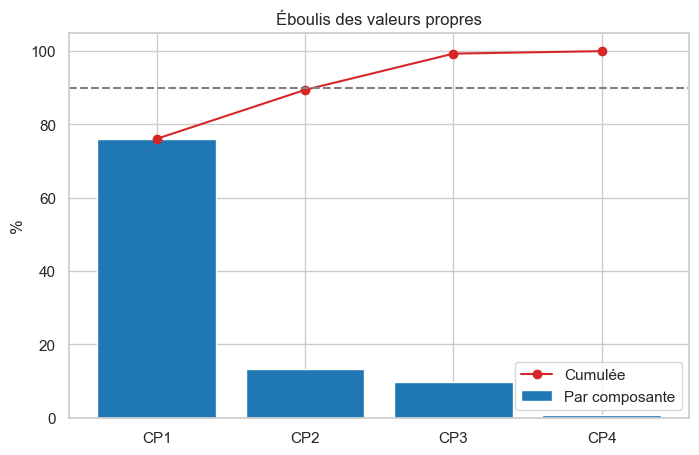

In [28]:
fig, ax = plt.subplots()
ax.bar(tab_acp.index, tab_acp["Variance expliquée (%)"], color="tab:blue", label="Par composante")
ax.plot(tab_acp.index, tab_acp["Variance cumulée (%)"], "o-", color="tab:red", label="Cumulée")
ax.axhline(90, ls="--", color="gray")
ax.set_ylabel("%")
ax.set_title("Éboulis des valeurs propres")
ax.legend()
plt.show()

**À retenir**
- L'ACP crée de nouvelles variables, combinaisons linéaires des variables d'origine, orthogonales entre elles.
- Les valeurs propres indiquent la part de variance captée par chaque composante.

## Partie 5 : Synthèse

| Méthode | Principe | Points forts | Limites | Quand l'utiliser |
|---|---|---|---|---|
| Corrélation avec la cible | Garder les variables liées au prix | Simple et rapide | Relations linéaires seulement, variables examinées une à une | Premier tri des variables |
| Suppression des redondances | Retirer une variable parmi deux très corrélées | Simplifie le modèle | Seuil à choisir | Avant toute régression |
| Ridge | Pénalité L2 | Stable en cas de multicolinéarité | Ne met aucune variable à zéro | Beaucoup de variables liées entre elles |
| Lasso | Pénalité L1 | Sélectionne les variables | Peut choisir l'une de deux variables liées au hasard | Sélection de variables et prédiction |
| ACP | Nouvelles variables de variance maximale | Visualisation, compression | Non supervisée, composantes peu interprétables | Visualiser, réduire le bruit |

**Règle de travail** : on standardise, on sépare apprentissage et test, on choisit les paramètres par validation croisée, et on ne juge le modèle que sur le test.